# Regression Trees
### Set up of data

We're taking the classic Titanic dataset

We did have to clean the data set by removing all unique columns

In [183]:
import numpy as np
import pandas as pd
import math
titanic = pd.read_csv('Titanic-Dataset.csv')

titanic.head()

# remove unique columns
titanic = titanic.drop(["PassengerId", "Name", "Cabin", "Ticket"], axis =1)
titanic["Age"] = titanic["Age"].fillna(titanic["Age"].median())
titanic["Embarked"] = titanic["Embarked"].fillna(titanic["Embarked"].mode()[0])

# change string columns to numbers
sex = {"female": 1, "male": 0}
embark = {"S": 0, "C": 1, "Q": -1}

titanic["Sex"] = titanic["Sex"].map(sex)
titanic["Embarked"] = titanic["Embarked"].map(embark)

# changing the name
data = titanic

data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,0,22.0,1,0,7.2500,0
1,1,1,1,38.0,1,0,71.2833,1
2,1,3,1,26.0,0,0,7.9250,0
3,1,1,1,35.0,1,0,53.1000,0
4,0,3,0,35.0,0,0,8.0500,0


Setting up the features and the target.

In [189]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Embarked"]
target = ["Fare"]

# split into training and testing 80/20?
data = data.sample(frac=1).reset_index(drop=True)

split = int(0.8 * len(data)) 

train = data[:split] 
test = data[split:] 

### Sum of Squared Residuals (SSR)

#### $SSR=\sum_{i=1}^n (y_i - \bar y)^2$


n = number of observations

$y_i$ = target value 

$\bar y$ = mean of the target values

![alt text](images/image1.svg)

In [ ]:
def ssr(target):
    # Calculate the mean of the target values
    mean = np.mean(target)

    # Calculate the squared residuals
    ssr = 0

    for value in target:
        residual = value - mean
        ssr += residual**2

    return ssr

# Example
fares = [10, 12, 14, 16, 18]
print("SSR for fares: ", ssr(fares))

SSR for fares:  40.0


We can use SSR as is or we can also use MSE (Mean Squared Error) as the splitting criteria. 

$MSE=\Large\frac{SSR}{n}$

For this assignment, we will use SSR as the splitting criteria. 


### Weighted SSR
After splitting the data into left and right groups, we calculate the SSR separately for each group and add the results together. This gives us the total remaining error after the split. The goal is to find the threshold that minimizes this combined SSR, as this means the target values within each resulting group are closer to their respective mean values, resulting in more accurate predictions.

$SSR_{split}=SSR_{left} + SSR_{right}$




In [ ]:
#LIVE CODE
def weighted_ssr_num(data, feature, target, min_samples_leaf=1):
    # Finds the best threshold for one numeric feature using SSR.
    # It returns (threshold, weighted_ssr) or (None, inf) if no valid split exists

    # Get unique values of the feature and sort them
    
    
        
      
        
        # To prevent overfitting, we set a minimum number of samples required in each leaf node.
        # If after splitting, either left or right has fewer samples than this minimum, we skip this threshold.
        

        # Calculate the weighted sum of squared residuals for this split
        

    return best_threshold, best_score

### Finding where to split
To find the best split for a numerical feature, we test different thresholds between its unique sorted values. For each threshold, the data is divided into two groups: values less than or equal to the threshold and values greater than it. We then calculate the weighted SSR for each split and select the threshold that produces the lowest total SSR.

In [ ]:
#LIVE CODE
def find_split(data, features, target, min_samples_leaf=1):
    # Finds the best feature and threshold using SSR

    

    # Iterate through each feature to find the best split
    
        # If a valid threshold is found and it improves the score, update the best split
        

    return best

In [ ]:
def data_split(data, feature, threshold):
    # Divides the DataFrame into left and right groups

    left = data[data[feature] <= threshold]
    right = data[data[feature] > threshold]

    return left, right

In [ ]:
#Might be deleted
best_split = find_split(train, features, "Fare", min_samples_leaf=5)

print(best_split)

print("Training observations:", len(train))
print("Weighted MSE:", best_split["score"] / len(train))

print("Training size:", len(train))
print("Root SSR:", ssr(train["Fare"].values))
print("Root MSE:", ssr(train["Fare"].values) / len(train))

{'feature': 'Pclass', 'threshold': np.float64(1.5), 'score': np.float64(1262254.8661354796), 'gain': np.float64(680310.0704925552)}
Training observations: 712
Weighted MSE: 1772.8298681678084
Training size: 712
Root SSR: 1942564.9366280348
Root MSE: 2728.321540207914


#### Displaying the result of the first (Root) split 

In [ ]:
root_ssr = ssr(train[target].values.ravel())

rows = []

for feature in features:
    threshold, score = weighted_ssr_num(
        train, feature, target
    )

    score = score.item()

    rows.append({
        "Feature": feature,
        "Best threshold": threshold,
        "SSR": round(score, 2),
        "SSR reduction": round(float(root_ssr - score), 2),
        "% of SSR removed": round(
            float(100 * (root_ssr - score) / root_ssr), 2
        )
    })

results = pd.DataFrame(rows).sort_values("SSR")

print(f"Root SSR: {float(root_ssr):.2f}")
display(results)

Root SSR: 1972203.01


,Feature,Best threshold,SSR,SSR reduction,% of SSR removed
0,Pclass,1.5,1265003.77,707199.24,35.86
5,Embarked,0.5,1813503.54,158699.46,8.05
4,Parch,0.5,1850575.46,121627.54,6.17
2,Age,34.5,1898831.51,73371.49,3.72
3,SibSp,0.5,1911018.79,61184.22,3.10
1,Sex,0.5,1915039.15,57163.85,2.90


### Graph Structure

Each node in the tree has an ID to identify its parent and children, a print method to display its information, and a resolve method to process an incoming data row and determine its prediction.

**Nodes**
Nodes represent the decision points of the tree. Each node stores the feature used for splitting, the threshold condition, the SSR of the parent data, and the SSR reduction (gain) achieved by the split.

Resolve checks the incoming data row against the node's condition (feature <= threshold) and passes the row to the corresponding child node. The data row continues down the tree until it reaches a leaf.

**Leaves**
Leaves are the endpoints of the tree branches. They store the prediction for the data reaching that leaf.

When a leaf is created, it receives the mean of the target values from its corresponding subset of data. This mean represents the predicted value for all observations reaching that leaf.

Resolve returns this prediction.

In [ ]:
import random

# Base class for all nodes in the tree
class Graph_Node:
    def __init__(self):
        self.id = random.randrange(100, 999) #unique identifier for the node, will be used when visualizing the tree

    def print(self):
        print(f"ID: {self.id}")

    def resolve(self, x=None):
        return None

# Class representing a decision node in the regression tree
class Node(Graph_Node):
    def __init__(self, feature: str, threshold, ssr, gain):
        self.feature = feature
        self.threshold = threshold
        self.ssr = ssr
        self.gain = gain #how much SSR decreases after splitting a node (= parent SSR - child SSR). A higher gain indicates a better split.

        self.id = random.randrange(100, 999)

    child1 : Graph_Node
    child2 : Graph_Node

    def print(self):
        print(f"ID: {self.id}")
        print(f"Feature: {self.feature}")
        print(f"Threshold: {self.threshold}")
        print(f"SSR: {self.ssr}")
        print(f"SSR reduction: {self.gain}")

        print(f"First child :  ({self.id})")
        self.child1.print()
        
        print(f"\nSecond child :  ({self.id})")
        self.child2.print()

    def set_children(self, child1: Graph_Node, child2: Graph_Node):
        self.child1 = child1
        self.child2 = child2

    def get_child1(self):
        return self.child1

    def get_child2(self):
        return self.child2
    
    #returns True is the observation belongs to the left child, False otherwise
    def get_if_split(self, x):
        return x[self.feature] <= self.threshold
    
    # returns the prediction for the observation x by traversing the tree from the current node down to a leaf node.
    def resolve(self, x):
        if self.get_if_split(x):
            return self.child1.resolve(x)

        return self.child2.resolve(x)

# Class representing a leaf node in the regression tree
class Leaf(Graph_Node):
    def __init__(self, prediction):
        self.prediction = prediction
        self.id = random.randrange(100, 999)

    def print(self):
        print(f"Leaf: ({self.id})")
        print(f"Prediction: {self.prediction}")

    def resolve(self, x=None):
        return self.prediction

### The Tree
We create the root by calling build_nodes on the training data. The function finds the best split, creates a decision node, divides the data, and recursively builds its children.

For each subset of data, we first check the stopping conditions:
- Has the maximum depth been reached (current_depth >= max_depth)?
- Are there too few data points to split the node (len(data) < min_samples_split)?
- Is there no valid split available?
- Does the best split provide no positive SSR reduction (gain <= 0)?
If any of these conditions are met, we create a leaf instead of another decision node. The leaf receives the mean of the target values in that subset as its prediction.

We also enforce min_samples_leaf when evaluating possible splits, ensuring that each resulting child contains at least the specified number of data points.

**Prediction**
To predict new data, each row is passed to the root node's resolve method. It follows the appropriate branches according to the splitting conditions until it reaches a leaf.

The leaf returns its stored mean target value as the prediction.

In [ ]:
# Class representing the regression tree
class Tree:
    def __init__(self, data: pd.DataFrame, features: list,
                target: list, max_depth: int, min_samples_split: int, min_samples_leaf: int):

        self.data = data
        self.features = features
        self.target = target
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split # Min samples required in a node to allow further splitting
        self.min_samples_leaf = min_samples_leaf # Min samples required for any resulting child node to remain a leaf
        self.root = None

    def get_root(self):
        return self.root

    def build_tree(self):
        self.root = self.build_nodes(self.data, current_depth=0)

    def build_nodes(self, data: pd.DataFrame, current_depth: int):
        # Calculate the mean fare for the current group
        prediction = np.mean(data[self.target].values).item()

        # Calculate the SSR of the current group
        node_ssr = ssr(data[self.target].values).item()

        # Stopping Conditions:
        # Stop if there are too few observations to split
        if len(data) < self.min_samples_split:
            return Leaf(prediction)

        # Stop if the maximum depth has been reached
        if current_depth >= self.max_depth:
            return Leaf(prediction)

        # Find the best feature and threshold
        split = find_split(
            data, self.features, self.target,
            self.min_samples_leaf
        )           

        # Stop if no valid split can be found
        if split is None:
            return Leaf(prediction)

        # Calculate the SSR reduction
        gain = np.asarray(split["gain"]).item()

        # Stop if the split does not improve SSR
        if gain <= 0:
            return Leaf(prediction)

        # Create the decision node
        parent = Node(
            split["feature"],
            split["threshold"],
            node_ssr,
            gain
        )

        # Divide the dataset into two groups
        child_data_1, child_data_2 = data_split(
            data,
            split["feature"],
            split["threshold"]
        )

        # Recursively build the two children
        current_depth += 1

        parent.set_children(
            self.build_nodes(child_data_1, current_depth),
            self.build_nodes(child_data_2, current_depth)
        )

        return parent

    def predict(self, new_data: pd.DataFrame):

        predictions = []

        # Go through each observation in the new dataset
        for index, row in new_data.iterrows():

            # Convert the row into a dictionary
            item = row.to_dict()

            # Follow the tree and get the prediction
            prediction = self.root.resolve(item)

            # Store the prediction
            predictions.append(prediction)

        return pd.Series(predictions, index=new_data.index, name="Prediction")

    def print(self):
            self.root.print()


### Lets Build

Using the irtitanicis set, let us build our tree and print our nodes.

In [ ]:
# Creating a regression tree
regression_tree = Tree(
    train,
    features,
    target,
    max_depth=3,
    min_samples_split=20,
    min_samples_leaf=5
)

regression_tree.build_tree()
regression_tree.print()

ID: 418
Feature: Pclass
Threshold: 1.5
SSR: 1942564.9366280348
SSR reduction: 680310.0704925552
First child :  (418)
ID: 552
Feature: Parch
Threshold: 0.5
SSR: 1185846.7113968944
SSR reduction: 156932.1421697915
First child :  (552)
ID: 509
Feature: Sex
Threshold: 0.5
SSR: 654051.0358133572
SSR reduction: 63604.74813464517
First child :  (509)
Leaf: (519)
Prediction: 51.85703125

Second child :  (509)
Leaf: (510)
Prediction: 97.32299999999998

Second child :  (552)
ID: 482
Feature: SibSp
Threshold: 0.5
SSR: 374863.53341374575
SSR reduction: 10471.092822184146
First child :  (482)
Leaf: (861)
Prediction: 124.82066923076923

Second child :  (482)
Leaf: (294)
Prediction: 155.70504210526315

Second child :  (418)
ID: 285
Feature: SibSp
Threshold: 0.5
SSR: 76408.15473858522
SSR reduction: 19737.543725358148
First child :  (285)
ID: 984
Feature: Parch
Threshold: 0.5
SSR: 26410.007828161437
SSR reduction: 2205.0920469384655
First child :  (984)
Leaf: (257)
Prediction: 10.4623284057971

Second

## Prediction

In [211]:
predictions = regression_tree.predict(test[features])

print(predictions.head())

712    10.462328
713    10.462328
714    10.462328
715    22.603765
716    10.462328
Name: Prediction, dtype: float64


In [197]:
new_data = titanic.iloc[25:,:]

new_data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
25,1,3,1,38.0,1,5,31.3875,0
26,0,3,0,28.0,0,0,7.2250,1
27,0,1,0,19.0,3,2,263.0000,0
28,1,3,1,28.0,0,0,7.8792,-1
29,0,3,0,28.0,0,0,7.8958,0


In [213]:
def compare(df: pd.DataFrame, target: str, predicted: str):

    # Calculate the difference between actual and predicted values
    df["Difference"] = df[target] - df[predicted]

    # Calculate the absolute difference
    df["Absolute Difference"] = abs(df["Difference"])

    return df

In [ ]:
# Display the comparison between actual and predicted values
prediction = regression_tree.predict(test[features])

comparison = test.copy()

comparison["Prediction"] = prediction

comparison = compare(comparison, "Fare", "Prediction")

display(comparison[["Fare", "Prediction", "Difference", "Absolute Difference"]].head(10))

,Fare,Prediction,Difference,Absolute Difference
712,8.0500,10.462328,-2.412328,2.412328
713,7.8958,10.462328,-2.566528,2.566528
714,7.7417,10.462328,-2.720628,2.720628
715,26.2500,22.603765,3.646235,3.646235
716,7.2292,10.462328,-3.233128,3.233128
717,26.5500,51.857031,-25.307031,25.307031
718,15.2458,19.541383,-4.295583,4.295583
719,29.1250,19.541383,9.583617,9.583617
720,7.8958,10.462328,-2.566528,2.566528
721,10.5000,10.462328,0.037672,0.037672


## Sklearn

In [200]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Actual values
y_true = test[target].values.ravel()

# Predictions from our own regression tree
custom_predictions = regression_tree.predict(test[features]).values

# Evaluation
custom_mae = mean_absolute_error(y_true, custom_predictions)
custom_mse = mean_squared_error(y_true, custom_predictions)
custom_rmse = np.sqrt(custom_mse)
custom_r2 = r2_score(y_true, custom_predictions)

print("Our Regression Tree")
print("MAE:", custom_mae)
print("MSE:", custom_mse)
print("RMSE:", custom_rmse)
print("R²:", custom_r2)

Our Regression Tree
MAE: 14.423188649706077
MSE: 794.7407433925704
RMSE: 28.19114654271036
R²: 0.4397352875284466


In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Separate features and target
X_train = train[features]
X_test = test[features]

y_train = train[target].values.ravel()
y_test = test[target].values.ravel()

# Create the Scikit-learn regression tree
regressor = DecisionTreeRegressor(
    max_depth=3,
    min_samples_split=20,
    min_samples_leaf=5,
    random_state=1
)

# Train the model
regressor.fit(train[features], train[target].values.ravel())

# Predictions from Scikit-learn
sklearn_predictions = regressor.predict(test[features])

# Evaluation
sklearn_mae = mean_absolute_error(y_true, sklearn_predictions)
sklearn_mse = mean_squared_error(y_true, sklearn_predictions)
sklearn_rmse = np.sqrt(sklearn_mse)
sklearn_r2 = r2_score(y_true, sklearn_predictions)

print("\nScikit-learn Regression Tree")
print("MAE:", sklearn_mae)
print("MSE:", sklearn_mse)
print("RMSE:", sklearn_rmse)
print("R²:", sklearn_r2)

# Comparing the performance of our regression tree with Scikit-learn's implementation
comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Our Tree": [custom_mae, custom_mse, custom_rmse, custom_r2],
    "Scikit-learn": [sklearn_mae, sklearn_mse, sklearn_rmse, sklearn_r2]
})

display(comparison)



Scikit-learn Regression Tree
MAE: 14.42318864970608
MSE: 794.7407433925705
RMSE: 28.191146542710364
R²: 0.4397352875284465


,Metric,Our Tree,Scikit-learn
0,MAE,14.423189,14.423189
1,MSE,794.740743,794.740743
2,RMSE,28.191147,28.191147
3,R²,0.439735,0.439735


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# The hyperparameter grid for regression
param_grid_reg = {
    'max_depth': range(1, 10, 1),
    'min_samples_leaf': range(1, 20, 2),
    'min_samples_split': range(2, 20, 2),
    'criterion': ["squared_error", "absolute_error"] 
}

# Initialize the regression tree
tree_reg = DecisionTreeRegressor(random_state=1)

# Set up GridSearchCV (using negative mean squared error as the scoring metric)
grid_search_reg = GridSearchCV(
    estimator=tree_reg, 
    param_grid=param_grid_reg, 
    cv=5, 
    scoring='neg_mean_squared_error', 
    verbose=True,
    error_score="raise"
)

# Fit it to our training data
grid_search_reg.fit(X_train, y_train)

print("Best Score (Negative MSE):", grid_search_reg.best_score_)
print("Best Parameters:", grid_search_reg.best_params_)
print("Best Regressor Configuration:")
print(grid_search_reg.best_estimator_)

best_mse = -grid_search_reg.best_score_
best_rmse = np.sqrt(best_mse)

print("Best MSE:", best_mse)
print("Best RMSE:", best_rmse)

Fitting 5 folds for each of 1620 candidates, totalling 8100 fits
Best Score (Negative MSE): -1511.994209102262
Best Parameters: {'criterion': 'squared_error', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Regressor Configuration:
DecisionTreeRegressor(max_depth=3, random_state=1)
Best MSE: 1511.994209102262
Best RMSE: 38.88436972746584


In [ ]:
# Using the best model to make predictions on the test set
best_model = grid_search_reg.best_estimator_
tuned_predictions = best_model.predict(X_test)

print(tuned_predictions[:10])

from sklearn.metrics import mean_absolute_error

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
print("Tuned Model MAE:", tuned_mae)

[164.8667  15.2458  21.075   39.6875  27.75    15.2458  11.5     15.2458
  26.25    13.    ]
Tuned Model MAE: 13.184444134078213


## Visualisation of the decision path


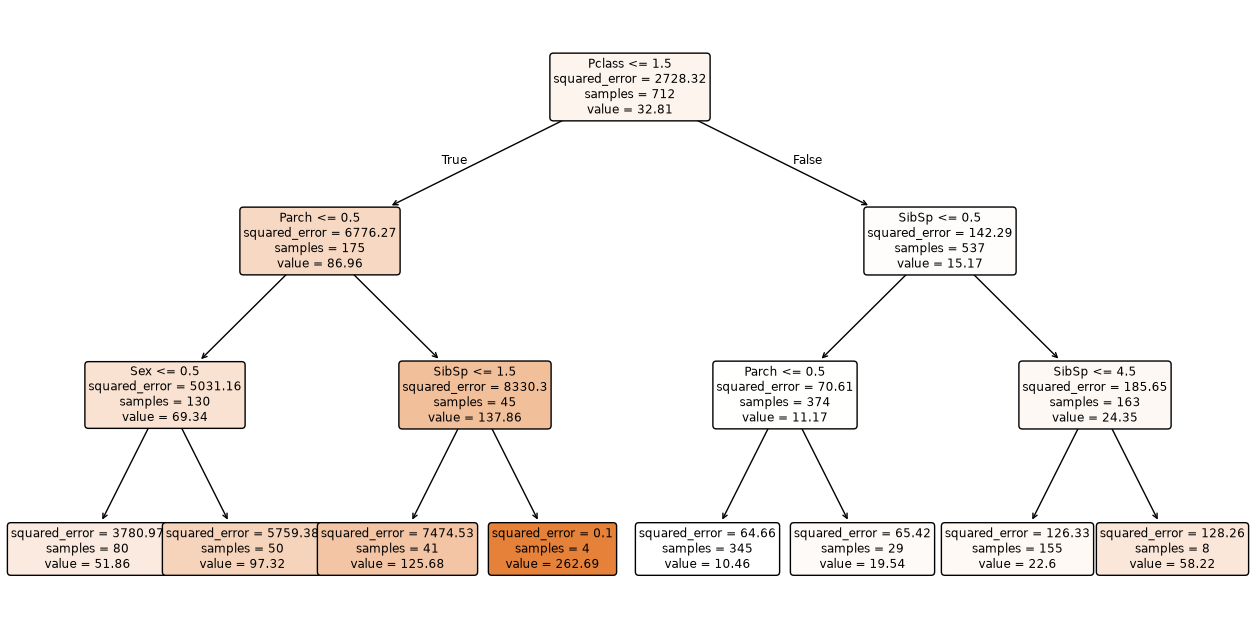

In [203]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Using the best tuned model from the grid search
tree_reg_best = grid_search_reg.best_estimator_

# the figure size
plt.figure(figsize=(16, 8))

# Plotting only the top 3 levels
plot_tree(
    tree_reg_best, 
    max_depth=3,            # Restricts the visual to the first 3 levels
    filled=True,            # Color codes nodes by predicted value intensity
    feature_names=features, 
    rounded=True,           
    precision=2             
)

plt.show()

In [ ]:
#An example showing how one passenger travels through the tree - Might be deleted
# Select one passenger from the test dataset
passenger = X_test.iloc[[0]]

# Display the passenger's characteristics
print("Passenger characteristics:")
display(passenger)

# Get the nodes visited by this passenger
path = tree_reg_best.decision_path(passenger)

# Get the ID of each visited node
node_ids = path.indices

# Get the ID of the final leaf
leaf_id = tree_reg_best.apply(passenger)[0]

# Access the internal structure of the tree
tree_structure = tree_reg_best.tree_

print("\nDecision path:")

# Go through each decision node (excluding the final leaf)
for node_id in node_ids[:-1]:

    # Identify which feature is being tested
    feature_id = tree_structure.feature[node_id]
    feature_name = features[feature_id]

    # Get the threshold
    threshold = tree_structure.threshold[node_id]

    # Get the passenger's value for this feature
    value = passenger.iloc[0][feature_name]

    # Determine which branch the passenger follows
    if value <= threshold:
        print(f"Node {node_id}: {feature_name} = {value:.2f} <= {threshold:.2f} -> LEFT")
    else:
        print(f"Node {node_id}: {feature_name} = {value:.2f} > {threshold:.2f} -> RIGHT")

# Get the predicted fare
predicted_fare = tree_reg_best.predict(passenger)[0]

print(f"\nFinal leaf: {leaf_id}")
print(f"Predicted fare: {predicted_fare:.2f}")


Passenger characteristics:


,Pclass,Sex,Age,SibSp,Parch,Embarked
712,3,0,43.0,0,0,0



Decision path:
Node 0: Pclass = 3.00 > 1.50 -> RIGHT
Node 8: SibSp = 0.00 <= 0.50 -> LEFT
Node 9: Parch = 0.00 <= 0.50 -> LEFT

Final leaf: 10
Predicted fare: 10.46


##  Analysis of Hyperparameters Impact in Sklearn
#### Individual hyperparameter impact
Lower RMSE indicates better performance.


In [204]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import numpy as np

# Prepare training data
X_train = train[features]
y_train = train[target].values.ravel()

# Fixed baseline parameters. Only the parameter being tested will be modified. 
baseline_depth = 3
baseline_split = 20
baseline_leaf = 1

max_depth - the maximum depth of the tree

In [205]:
# Values of max_depth to test
depth_values = range(1, 11)

depth_rmse = []

for depth in depth_values:

    # Create a tree with the current max_depth
    regressor = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_split=baseline_split,
        min_samples_leaf=baseline_leaf,
        random_state=1
    )

    # Perform 5-fold cross-validation
    scores = cross_val_score(
        regressor,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    # Convert negative MSE to RMSE
    rmse = np.sqrt(-scores.mean())

    depth_rmse.append(rmse)

# Display results
depth_results = pd.DataFrame({
    "Max Depth": list(depth_values),
    "RMSE": depth_rmse
})

depth_results["RMSE"] = depth_results["RMSE"].round(2)

display(depth_results.sort_values("RMSE").reset_index(drop=True))

,Max Depth,RMSE
0,3,39.24
1,4,39.71
2,2,40.88
3,6,42.16
4,1,42.19
5,7,42.29
6,8,42.30
7,9,42.31
8,10,42.31
9,5,42.34


The best result was achieved with a maximum depth of 3. Increasing the depth beyond this did not improve performance, instead, RMSE  increased. A relatively shallow tree is sufficient for this dataset.

min_samples_split - the minimum number of observations required in a node before it can be split

In [206]:
# Values of min_samples_split to test
split_values = [2, 5, 10, 20, 30, 50, 75, 100]

split_rmse = []

for minimum in split_values:

    regressor = DecisionTreeRegressor(
        max_depth=baseline_depth,
        min_samples_split=minimum,
        min_samples_leaf=baseline_leaf,
        random_state=1
    )

    scores = cross_val_score(
        regressor,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    rmse = np.sqrt(-scores.mean())
    split_rmse.append(rmse)

# Display results
split_results = pd.DataFrame({
    "Min Samples Split": split_values,
    "RMSE": split_rmse
})

split_results["RMSE"] = split_results["RMSE"].round(2)

display(split_results.sort_values("RMSE").reset_index(drop=True))

,Min Samples Split,RMSE
0,2,38.88
1,5,38.88
2,10,38.88
3,20,39.24
4,30,39.24
5,50,40.35
6,75,40.35
7,100,40.36


The lowest RMSE was obtained with values of 2, 5 and 10. As the minimum number of samples required to split increases, performance becomes worse. This suggests that allowing more splits was beneficial for this dataset.

min_samples_leaf - the minimum number of training observations that must be present in each leaf

In [207]:
# Values of min_samples_leaf to test
leaf_values = [1, 2, 3, 5, 10, 15, 20, 30, 50]

leaf_rmse = []

for minimum in leaf_values:

    regressor = DecisionTreeRegressor(
        max_depth=baseline_depth,
        min_samples_split=baseline_split,
        min_samples_leaf=minimum,
        random_state=1
    )

    scores = cross_val_score(
        regressor,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    rmse = np.sqrt(-scores.mean())
    leaf_rmse.append(rmse)

# Display results
leaf_results = pd.DataFrame({
    "Min Samples Leaf": leaf_values,
    "RMSE": leaf_rmse
})

leaf_results["RMSE"] = leaf_results["RMSE"].round(2)

display(leaf_results.sort_values("RMSE").reset_index(drop=True))

,Min Samples Leaf,RMSE
0,30,38.84
1,20,38.88
2,1,39.24
3,2,39.24
4,3,40.42
5,15,40.79
6,5,41.54
7,10,41.56
8,50,41.62


Smaller leaf sizes performed better. Increasing the minimum number of observations per leaf generally increased RMSE, suggesting that restricting the tree too much reduced its predictive performance.

#### GridSearchCV

In [208]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# The hyperparameter grid for regression
param_grid_reg = {
    'max_depth': range(1, 10, 1),
    'min_samples_leaf': range(1, 20, 2),
    'min_samples_split': range(2, 20, 2),
    'criterion': ["squared_error"] #if we include absolute_error, it will give different results, showing that a different splitting criteria can improve performance.
}

# Initialize the regression tree
tree_reg = DecisionTreeRegressor(random_state=1)

# Set up GridSearchCV (using negative mean squared error as the scoring metric)
grid_search_reg = GridSearchCV(
    estimator=tree_reg, 
    param_grid=param_grid_reg, 
    cv=5, 
    scoring='neg_mean_squared_error', 
    verbose=True,
    error_score="raise"
)

# Fit it to your training data
grid_search_reg.fit(X_train, y_train)

print("Best Score (Negative MSE):", grid_search_reg.best_score_)
print("Best Parameters:", grid_search_reg.best_params_)
print("Best Regressor Configuration:")
print(grid_search_reg.best_estimator_)

best_mse = -grid_search_reg.best_score_
best_rmse = np.sqrt(best_mse)

print("Best MSE:", best_mse)
print("Best RMSE:", best_rmse)

Fitting 5 folds for each of 810 candidates, totalling 4050 fits
Best Score (Negative MSE): -1511.994209102262
Best Parameters: {'criterion': 'squared_error', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Regressor Configuration:
DecisionTreeRegressor(max_depth=3, random_state=1)
Best MSE: 1511.994209102262
Best RMSE: 38.88436972746584


According to GridSearchCV, a regression tree with a maximum depth of 3, a minimum of 2 samples required to split a node, and a minimum of 1 sample per leaf is the best configuration.

In [209]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Get the best model
best_regressor = grid_search_reg.best_estimator_

# Make predictions on test data
best_predictions = best_regressor.predict(test[features])

# Evaluate performance
best_mae = mean_absolute_error(test[target].values.ravel(), best_predictions)
best_mse = mean_squared_error(test[target].values.ravel(), best_predictions)
best_rmse = np.sqrt(best_mse)
best_r2 = r2_score(test[target].values.ravel(), best_predictions)

print("Optimised Regression Tree")
print("MAE:", best_mae)
print("MSE:", best_mse)
print("RMSE:", best_rmse)
print("R²:", best_r2)

Optimised Regression Tree
MAE: 12.996532854340737
MSE: 630.6930578658158
RMSE: 25.11360304428291
R²: 0.5553832269695871


## Linear trees 
- Regression tree: Each leaf predicts the mean of the target values belonging to that leaf. All observations reaching the same leaf receive the same prediction.

- Linear tree: Each leaf contains a linear regression equation. Predictions depend on the input feature values, so observations reaching the same leaf can receive different predictions.

**Example**
2 passengers reach the same leaf.

In a regular regression tree, both would receive the same predicted fare: e.g., fare = 25

In a linear tree, the leaf might contain: fare = 5+2(Age)

A passenger aged 20 would receive a prediction of 45, while a passenger aged 30 would receive a prediction of 65.

(Numbers are illustrative.)


**Advantages**: 	
- Can capture linear relationships within groups of data	
- More complex than ordinary regression trees
- Can produce more flexible predictions	

**Disadvantages**: 
- Requires fitting regression models in each leaf
- Combines decision-tree splitting with linear regression	
- Can overfit, especially with small leaf samples